![](img/banner.png)

# Exhaustive clustering: enumeration, counting, and pruning

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad


## Why this notebook?

In [Clustering-Part1](Clustering-Part1.ipynb) we *used* a clustering algorithm, and
in one sentence we said that finding the best clustering by trying every
possibility is "clearly infeasible", because there are too many partitions. This
page stops at that sentence and takes it seriously.

Three ideas carry everything that follows:

1. a clustering is a **discrete object** — a vector of labels — so "try
   everything" is a loop over vectors of length $n$;
2. **recursion** writes that loop without writing $n$ nested loops, and
   **Stirling numbers of the second kind** count how many candidates there are;
3. **pruning** — testing constraints *before* doing the work — is what makes a
   discrete search practical, and it is the same idea that separates a clever
   search from a hopeless one.

At the end we solve the 2-clustering problem **exactly** on small data. That
exact answer is the only honest way to say whether a heuristic such as k-means
did well or badly, and it is what the rest of the clustering chapter builds on.


## 1. A clustering is a discrete object

Let $\mathbf{D} = \{\mathbf{x}_1,\ldots,\mathbf{x}_n\}$ be our data and let $k$
be the number of groups we want. A clustering is a partition
$\mathcal{C} = \{C_1,\ldots,C_k\}$ of the data points: every point is in exactly
one cluster, and no cluster is empty.

A program does not store a family of sets. It stores a **label vector**

$$
\mathbf{z} = (z_1, z_2, \ldots, z_n), \qquad z_i \in \{1,2,\ldots,k\},
$$

and the partition is recovered as $C_j = \{\mathbf{x}_i : z_i = j\}$. For
$n=3$ and labels $0/1$, the vector `[0, 1, 1]` says: point 0 alone in cluster 0,
points 1 and 2 together in cluster 1.

Two facts are easy to forget and they decide how we count:

- **Labels are names, not numbers.** Swapping the names $1$ and $2$ in
  $\mathbf{z}$ does not change the partition. A partition with $k$ blocks can be
  written with $k!$ different label vectors, so counting label vectors
  *over-counts* partitions by a factor $k!$.
- **Empty clusters are not clusters.** $\mathbf{z} = (1,1,\ldots,1)$ describes
  one cluster, not $k$. Requiring exactly $k$ clusters means requiring all $k$
  labels to appear.

Still, *searching* over label vectors is the natural thing for a computer: the
search space is a vector of $n$ integers with $k$ values each, and optimization
means "among all of them, find the one with the smallest cost".


## 2. Truth tables: the simplest discrete search space

Take $k=2$, so every label is a bit. A vector of $n$ bits is a row of the
**truth table** of $n$ Boolean variables. For three variables there are
$2^3 = 8$ rows, and three nested loops write them all:


In [1]:
for z1 in range(2):
    for z2 in range(2):
        for z3 in range(2):
            print(z1, z2, z3)


0 0 0
0 0 1
0 1 0
0 1 1
1 0 0
1 0 1
1 1 0
1 1 1


This does not generalize: for $n=50$ we would need fifty nested loops. What we
need is *one* loop that decides the first bit and then hands the rest of the job
to the same code. A function that calls itself is called **recursive**, and it
always has two parts:

* the **base case**: the smallest instance, solved directly — here "all $n$
  decisions are made", i.e. `i == n`, so we record the row;
* the **recursive case**: make one decision (fix `x[i]`), then call the function
  on the remaining decisions.

Trace $n=2$ by hand. `SAT_Table(x, 0)` sets `x[0] = 0` and calls
`SAT_Table(x, 1)`; that call sets `x[1] = 0` and calls `SAT_Table(x, 2)`, whose
base case prints `[0, 0]`. Back at level 1 the loop moves on, `x[1] = 1` gives
`[0, 1]`, and level 1 is finished. Back at level 0 the loop moves on, `x[0] = 1`,
and the same two rows appear with a leading 1: four rows in total, $2^2$.


In [2]:
def SAT_Table(x, i):
    """Print every truth-table row that agrees with x on the first i entries."""
    if i == len(x):            # base case: nothing left to decide
        print(x)
    else:                      # recursive case: decide x[i], then the rest
        for x[i] in range(2):
            SAT_Table(x, i + 1)


x = [0] * 3
SAT_Table(x, 0)


[0, 0, 0]
[0, 0, 1]
[0, 1, 0]
[0, 1, 1]
[1, 0, 0]
[1, 0, 1]
[1, 1, 0]
[1, 1, 1]


`for x[i] in range(2)` is shorthand for `for value in range(2): x[i] = value`.
The list `x` is created **once** and travels through the whole recursion; each
level owns exactly one cell of it. That is why the code is short — and it is also
the source of the bug in Section 4.


## 3. First attempt at *returning* the rows: a classic bug

Printing is not enough: we want to *use* the rows, for example to score each
clustering. The natural change is to return the row instead of printing it.


In [3]:
def SAT_Table_wrong(x, i):
    if i == len(x):
        return x
    else:
        for x[i] in range(2):
            return SAT_Table_wrong(x, i + 1)


print(SAT_Table_wrong([0, 0, 0], 0))


[0, 0, 0]


Only one row appears, `[0, 0, 0]`, not eight. `return` **ends the function**.
The first time the loop body runs it executes `return SAT_Table_wrong(x, 1)`, and
when that call comes back the function is over: the assignment `x[0] = 1` is
never reached. A function that must produce *many* answers cannot return after
the first one.

There are two standard repairs: collect the answers in a list, or turn the
function into a generator. Both are worth knowing, because the second one is what
we use from now on.

### Repair A: collect the rows in a list


In [4]:
def SAT_Table_list(x, i, rows):
    if i == len(x):
        rows.append(list(x))        # list(x) makes a copy -- see Section 5
    else:
        for x[i] in range(2):
            SAT_Table_list(x, i + 1, rows)
    return rows


rows = SAT_Table_list([0, 0, 0], 0, [])
print(rows)
print("number of rows:", len(rows))


[[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]]
number of rows: 8


This works, with two small annoyances: the extra parameter `rows` must be
carried through every call, and it is very easy to write `rows.append(x)`
instead of `rows.append(list(x))`. That mistake deserves its own section.

## 4. The aliasing trap: eight rows that are all the same

Look carefully at the next function. The only difference from the previous one is
that it appends `x` instead of `list(x)`.


In [5]:
def SAT_Table_ref(x, i, rows):
    if i == len(x):
        rows.append(x)              # no copy: a reference to x is stored
    else:
        for x[i] in range(2):
            SAT_Table_ref(x, i + 1, rows)
    return rows


rows = SAT_Table_ref([0, 0, 0], 0, [])
print("number of rows:", len(rows))
for r in rows:
    print(r)


number of rows: 8
[1, 1, 1]
[1, 1, 1]
[1, 1, 1]
[1, 1, 1]
[1, 1, 1]
[1, 1, 1]
[1, 1, 1]
[1, 1, 1]


In [6]:
print("distinct objects stored:", len({id(r) for r in rows}))


distinct objects stored: 1


Eight rows were appended, but there is only **one** list object: every entry of
`rows` is a reference to the same `x`, and when the recursion finished `x` held
the last row it visited, `[1, 1, 1]`. All eight saved "rows" therefore print
`[1, 1, 1]`.

This is the most common bug in recursive enumeration, and it is invisible while
we print inside the function, because there we look at `x` at the moment when it
is correct. The bug appears only when we *store* the value. Rule: when a function
writes into a shared buffer, store a **copy** (`list(x)`, `x.copy()`,
`tuple(x)`), never the buffer itself.

### Repair B: a generator (`yield`)

A function that contains `yield` becomes a **generator**. Calling it does not run
the body; it returns an object that produces one value each time it is asked.
`yield` is like `return`, except that the function is not destroyed: it is
suspended and continues from the same place at the next request. `yield from`
delegates to another generator, passing every value it produces on to the caller.


In [7]:
def SAT_Table_gen(x, i):
    """Generate every truth-table row that agrees with x on the first i entries."""
    if i == len(x):
        yield list(x)               # a copy, so the caller may keep it
    else:
        for x[i] in range(2):
            yield from SAT_Table_gen(x, i + 1)


for row in SAT_Table_gen([0, 0, 0], 0):
    print(row)


[0, 0, 0]
[0, 0, 1]
[0, 1, 0]
[0, 1, 1]
[1, 0, 0]
[1, 0, 1]
[1, 1, 0]
[1, 1, 1]


The generator is *lazy*: values are produced on demand, so we may stop early and
we never hold all rows in memory at once.


In [8]:
gen = SAT_Table_gen([0, 0, 0], 0)
print(next(gen))
print(next(gen))
print("the generator is now suspended in the middle of the recursion")


[0, 0, 0]
[0, 0, 1]
the generator is now suspended in the middle of the recursion


## 5. How many rows? $2^n$

For $n$ Boolean variables the truth table has exactly $2^n$ rows, one per subset of
the variables that are set to 1. Counting the generated rows confirms it — and
shows how quickly enumeration becomes hopeless:

| $n$ | $2^n$ |
|---|---|
| 10 | 1 024 |
| 20 | 1 048 576 |
| 30 | 1 073 741 824 |
| 50 | $1.13\times10^{15}$ |
| 100 | $1.27\times10^{30}$ |

An image with $200\times300$ pixels has $n = 60\,000$ points, so even the
*binary* space has $2^{60000}$ labelings. Comparing one labeling per nanosecond
would take longer than the age of the universe, by a lot.


In [9]:
for n in range(1, 13):
    count = sum(1 for _ in SAT_Table_gen([0] * n, 0))
    print(f"n = {n:>2}   rows = {count:>6}   2**n = {2 ** n:>6}")


n =  1   rows =      2   2**n =      2
n =  2   rows =      4   2**n =      4
n =  3   rows =      8   2**n =      8
n =  4   rows =     16   2**n =     16
n =  5   rows =     32   2**n =     32
n =  6   rows =     64   2**n =     64
n =  7   rows =    128   2**n =    128
n =  8   rows =    256   2**n =    256
n =  9   rows =    512   2**n =    512
n = 10   rows =   1024   2**n =   1024
n = 11   rows =   2048   2**n =   2048
n = 12   rows =   4096   2**n =   4096


## 6. Counting clusterings: Stirling numbers of the second kind

A truth-table row is a *labeled* assignment: bit $i$ says which of two groups
point $i$ belongs to. A **clustering** is a *partition*: a family of non-empty
blocks with no names attached. The number of partitions of $n$ distinct objects
into exactly $k$ non-empty blocks is the **Stirling number of the second kind**

$$
S(n,k) = \left\{ \begin{matrix} n \\ k \end{matrix} \right\}.
$$

> **Mind the name.** *Stirling's formula* (or *approximation*) is
> $n! \approx \sqrt{2\pi n}\,(n/e)^n$, an estimate for the factorial. *Stirling
> numbers* are something else: counts of permutations (first kind) and of
> partitions (second kind). This course only needs the second kind, written
> $S(n,k)$.

| $n \backslash k$ | 1 | 2 | 3 | 4 | 5 | $\sum_k S(n,k)$ |
|---|---|---|---|---|---|---|
| 1 | 1 | | | | | 1 |
| 2 | 1 | 1 | | | | 2 |
| 3 | 1 | 3 | 1 | | | 5 |
| 4 | 1 | 7 | 6 | 1 | | 15 |
| 5 | 1 | 15 | 25 | 10 | 1 | 52 |
| 6 | 1 | 31 | 90 | 65 | 15 | 203 |

Each row adds up to a **Bell number** $B_n = \sum_{k=1}^{n} S(n,k)$: the number of
clusterings of $n$ points when $k$ is not fixed in advance. The sequence
$1, 2, 5, 15, 52, 203, 877, 4140, 21147, 115975,\ldots$ is still small for tiny
data — for $n=10$ there are only 115 975 clusterings — and that is exactly what
the exhaustive search at the end of this page exploits.

### The recurrence

Look at object $n$ (the last one). In a partition into $k$ blocks there are two
possibilities:

1. object $n$ is **alone**: the other $n-1$ objects form a partition into $k-1$
   blocks, $S(n-1,k-1)$ ways;
2. object $n$ is **not alone**: remove it, the rest form a partition into $k$
   blocks ($S(n-1,k)$ ways), and object $n$ may join any of those $k$ blocks:
   $k\,S(n-1,k)$ ways.

The cases are disjoint, so

$$
S(n,k) = k\,S(n-1,k) + S(n-1,k-1),
$$

with $S(n,1) = S(n,n) = 1$ and $S(n,k) = 0$ for $k > n$. This is "split the last
decision into cases", the same style of thinking as the recursion above.


In [10]:
def S(n, k):
    """Stirling number of the second kind: partitions of n objects into k blocks."""
    if k == 0:
        return 1 if n == 0 else 0
    if k > n:
        return 0
    if k == 1 or k == n:
        return 1
    return k * S(n - 1, k) + S(n - 1, k - 1)


print("S(3, 2)  =", S(3, 2))
print("S(4, 2)  =", S(4, 2))
print("S(15, 3) =", S(15, 3))


S(3, 2)  = 3
S(4, 2)  = 7
S(15, 3) = 2375101


$S(3,2)=3$ is easy to check by hand: $\{1\}|\{2,3\}$, $\{2\}|\{1,3\}$ and
$\{3\}|\{1,2\}$.

### A closed form

The recurrence is not the only formula. Counting the assignments that use $k$
labels and hit all of them (inclusion and exclusion over the missed labels), then
dividing by $k!$ to forget the names of the labels, gives

$$
S(n,k) = \frac{1}{k!}\sum_{j=0}^{k} (-1)^j \binom{k}{j} (k-j)^n .
$$

Agreement of the two formulas is a good test of both:


In [11]:
import math


def S_closed(n, k):
    return sum((-1) ** j * math.comb(k, j) * (k - j) ** n
               for j in range(k + 1)) // math.factorial(k)


agree = all(S(n, k) == S_closed(n, k) for n in range(1, 12) for k in range(1, n + 1))
print("recurrence and closed form agree:", agree)


recurrence and closed form agree: True


### Two identities used later

**Two clusters.** For $k=2$: in a partition into two blocks, the block of point 1
is determined by which of the points $2,\ldots,n$ join it ($2^{n-1}$ choices), and
a subset and its complement give the same partition, hence

$$S(n,2) = 2^{n-1} - 1 .$$

**Labelings versus partitions.** Choosing one of $k$ labels for each of $n$ points
gives $k^n$ labelings. Such a labeling uses some $j\le k$ labels
($\binom{k}{j}$ choices), splits the points into $j$ non-empty blocks
($S(n,j)$ ways) and names those blocks ($j!$ ways):

$$k^n = \sum_{j=1}^{k}\binom{k}{j}\, j!\, S(n,j).$$


In [12]:
ns = list(range(2, 13))
print("S(n, 2)      :", [S(n, 2) for n in ns])
print("2**(n-1) - 1 :", [2 ** (n - 1) - 1 for n in ns])


S(n, 2)      : [1, 3, 7, 15, 31, 63, 127, 255, 511, 1023, 2047]
2**(n-1) - 1 : [1, 3, 7, 15, 31, 63, 127, 255, 511, 1023, 2047]


In [13]:
n, k = 7, 4
print("k**n                =", k ** n)
print("sum over partitions =", sum(math.comb(k, j) * math.factorial(j) * S(n, j)
                                  for j in range(1, k + 1)))


k**n                = 16384
sum over partitions = 16384


## 7. Why the plain recursion is slow: overlapping subproblems

`S` is short and correct, but redundant. The calls `S(n-1,k)` and `S(n-1,k-1)`
both eventually need `S(n-2,k-1)`, and each of them computes it again. Count how
many times the function is entered:


In [14]:
calls = 0


def S_count(n, k):
    global calls
    calls += 1
    if k > n:
        return 0
    if k == 1 or k == n:
        return 1
    return k * S_count(n - 1, k) + S_count(n - 1, k - 1)


for n, k in [(10, 3), (15, 4), (16, 6), (18, 8), (20, 10)]:
    calls = 0
    value = S_count(n, k)
    print(f"S({n}, {k}) = {value:>20}   function calls = {calls:>7}")


S(10, 3) =                 9330   function calls =      71
S(15, 4) =             42355950   function calls =     727
S(16, 6) =           2734926558   function calls =    6005
S(18, 8) =         189036065010   function calls =   38895
S(20, 10) =        5917584964655   function calls =  184755


For $S(20,10)$ there are only about $20\times10 = 200$ *different* subproblems
$(n,k)$, yet the recursion is entered 184 755 times. The cost is exponential in
$k$, not in $n$.

**Memoization** stores the answer of each subproblem the first time it is
computed. In Python that is one line:


In [15]:
from functools import lru_cache


@lru_cache(maxsize=None)
def S_memo(n, k):
    if k == 0:
        return 1 if n == 0 else 0
    if k > n:
        return 0
    if k == 1 or k == n:
        return 1
    return k * S_memo(n - 1, k) + S_memo(n - 1, k - 1)


S_memo.cache_clear()
print("S_memo(20, 10) =", S_memo(20, 10))
print("distinct subproblems computed:", S_memo.cache_info().currsize)
print("S_memo(150, 3) =", S_memo(150, 3))


S_memo(20, 10) = 5917584964655
distinct subproblems computed: 109
S_memo(150, 3) = 61664747505854495487450129694992261011432242869144177577783166025584730


In [16]:
import time

t0 = time.perf_counter()
S(21, 10)
t1 = time.perf_counter()
S_memo.cache_clear()
t2 = time.perf_counter()
S_memo(21, 10)
t3 = time.perf_counter()
print(f"without memoization: {t1 - t0:.3f} s")
print(f"with memoization:    {t3 - t2:.6f} s")


without memoization: 0.029 s
with memoization:    0.000077 s


The same idea appears all over the course: dynamic programming, the Viterbi
algorithm and the "cache" of a recursive search are all memoized recursions. The
price is memory, one entry per subproblem.

## 8. How large is a clustering problem?

Sorting 150 points into 3 clusters:


In [17]:
print("S(150, 3) =", S(150, 3))
print("number of digits:", len(str(S(150, 3))))


S(150, 3) = 61664747505854495487450129694992261011432242869144177577783166025584730
number of digits: 71


In [18]:
per_second = 10 ** 9                      # one billion clusterings scored per second
years = S(150, 3) / per_second / (3600 * 24 * 365)
print(f"time needed: {years:.2e} years")


time needed: 1.96e+54 years


The age of the universe is about $1.4\times10^{10}$ years, so this is hopeless by
a factor of $10^{44}$. And $k=3$ is the *easy* case: the number of clusterings of
150 points into *any* number of clusters is $B_{150}$, which has about 150 digits.

This is the quantitative reason why every clustering chapter, after stating the
problem, turns immediately to heuristics: k-means, hierarchical clustering, LVQ
{cite}`zaki2020data`. Exhaustive search keeps two honest uses, and they are the
subject of the rest of this page: on *tiny* data it gives the true optimum, which
we can use to test a heuristic; and theoretically it defines the problem —
"clustering" *means* minimizing a cost over the set of partitions, and the count
tells us how large that set is.


## 9. From a labeling to a clustering

The recipe for the rest of the page is short:

1. enumerate all labelings of the $n$ points with the labels $0$ and $1$;
2. discard the labelings that do not describe two non-empty clusters;
3. score the rest with a cost, here the within-cluster sum of squares;
4. keep the minimum.

Step 1 is the generator from Section 4:


In [19]:
def labelings_2(x, i=0):
    """All 0/1 vectors of length len(x), one at a time."""
    if i == len(x):
        yield list(x)               # a copy, not the shared buffer
    else:
        for x[i] in range(2):
            yield from labelings_2(x, i + 1)


for z in labelings_2([0, 0, 0]):
    print(z)


[0, 0, 0]
[0, 0, 1]
[0, 1, 0]
[0, 1, 1]
[1, 0, 0]
[1, 0, 1]
[1, 1, 0]
[1, 1, 1]


Eight rows, as expected: $2^3$. But not all of them are clusterings. A labeling
is a vector of labels; a clustering is a list of blocks that contain *indices* of
points. The conversion is a list comprehension over the labels:


In [20]:
def to_clusters(z):
    """[0, 1, 1, 0] -> [[0, 3], [1, 2]] : the point indices of each cluster."""
    k = max(z) + 1
    return [[i for i, label in enumerate(z) if label == b] for b in range(k)]


In [21]:
for z in labelings_2([0, 0, 0]):
    print(z, "->", to_clusters(z))


[0, 0, 0] -> [[0, 1, 2]]
[0, 0, 1] -> [[0, 1], [2]]
[0, 1, 0] -> [[0, 2], [1]]
[0, 1, 1] -> [[0], [1, 2]]
[1, 0, 0] -> [[1, 2], [0]]
[1, 0, 1] -> [[1], [0, 2]]
[1, 1, 0] -> [[2], [0, 1]]
[1, 1, 1] -> [[], [0, 1, 2]]


Two of the eight labelings, `[0,0,0]` and `[1,1,1]`, use a single label: they
describe **one** cluster, not two. The other six come in pairs such as `[0,1,1]`
and `[1,0,0]`, which are the *same* split $\{1\}|\{2,3\}$ with the cluster names
swapped. Since we look for partitions and not labelings, we keep one of each pair:


In [22]:
def clusterings_2(n):
    """All partitions of {0,...,n-1} into exactly two non-empty blocks."""
    for z in labelings_2([0] * n):
        blocks = to_clusters(z)
        if len(blocks) < 2 or len(blocks[0]) == 0 or len(blocks[1]) == 0:
            continue
        if 0 not in blocks[0]:          # keep only one of the two labelings
            continue
        yield blocks


for blocks in clusterings_2(3):
    print(blocks)


[[0, 1], [2]]
[[0, 2], [1]]
[[0], [1, 2]]


## 10. How many candidates? $2^n$ or $2^{n-1}-1$?

The number of 0/1 vectors is $2^n$. Half of them are complements of the other half
(the same partition with the labels swapped) and two are constant (one cluster).
What remains is

$$S(n,2) = 2^{n-1}-1,$$

the identity proved above. Counting the output of the generator confirms both the
formula and the code:


In [23]:
for n in range(2, 11):
    produced = sum(1 for _ in clusterings_2(n))
    print(f"n = {n:>2}   produced = {produced:>5}   2**(n-1) - 1 = {2 ** (n - 1) - 1:>5}")


n =  2   produced =     1   2**(n-1) - 1 =     1
n =  3   produced =     3   2**(n-1) - 1 =     3
n =  4   produced =     7   2**(n-1) - 1 =     7
n =  5   produced =    15   2**(n-1) - 1 =    15
n =  6   produced =    31   2**(n-1) - 1 =    31
n =  7   produced =    63   2**(n-1) - 1 =    63
n =  8   produced =   127   2**(n-1) - 1 =   127
n =  9   produced =   255   2**(n-1) - 1 =   255
n = 10   produced =   511   2**(n-1) - 1 =   511


In [24]:
for n in [5, 10, 20, 30, 40, 50]:
    print(f"n = {n:>2}   labelings = {2 ** n:>17}   clusterings = {2 ** (n - 1) - 1:>17}")


n =  5   labelings =                32   clusterings =                15
n = 10   labelings =              1024   clusterings =               511
n = 20   labelings =           1048576   clusterings =            524287
n = 30   labelings =        1073741824   clusterings =         536870911
n = 40   labelings =     1099511627776   clusterings =      549755813887
n = 50   labelings =  1125899906842624   clusterings =   562949953421311


The right-hand column is the number of *candidate solutions* of the 2-clustering
problem, and it doubles with every new point. For $n=50$ it is already
$5.6\times10^{14}$; for the $n=60\,000$ pixels of a small image it is a number with
18 000 digits. Enumeration is a tool for understanding tiny problems, not for real
data.

## 11. The cost: within-cluster sum of squares

We need a number that says how good a clustering is. The standard choice (see
[Clustering-Part2](Clustering-Part2.ipynb)) is the **within-cluster sum of
squares**: for a cluster $C$ with centroid $\boldsymbol\mu_C$,

$$
W(C) = \sum_{\mathbf{x}\in C}\|\mathbf{x}-\boldsymbol\mu_C\|^2,
\qquad
\text{cost}(\mathcal{C}) = \sum_{j=1}^{k} W(C_j).
$$

It is also called SSE (sum of squared errors) or WCSS. A point is a tuple of
coordinates, so 1-D data is simply a set of 1-tuples such as `(10,)`. Writing the
code for tuples from the beginning means nothing changes when the data become 2-D
or 20-D.


In [25]:
def sq_dist(a, b):
    """Squared Euclidean distance between two points (tuples of equal length)."""
    return sum((ai - bi) ** 2 for ai, bi in zip(a, b))


def dist(a, b):
    return math.sqrt(sq_dist(a, b))


def centroid(C):
    """Coordinate-wise mean of a list of points."""
    m = len(C)
    return tuple(sum(p[d] for p in C) / m for d in range(len(C[0])))


def wcss(D, idx):
    """Within-cluster sum of squares of the points of D selected by idx."""
    if not idx:
        return 0.0
    C = [D[i] for i in idx]
    mu = centroid(C)
    return sum(sq_dist(p, mu) for p in C)


**A remark that saves half the work.** There is a second way to write the same
quantity: sum the squared distances over all *pairs* inside the cluster. Lemma 2
of [Clustering-Part2](Clustering-Part2.ipynb) says

$$
\sum_{i<j}\|\mathbf{x}_i-\mathbf{x}_j\|^2
= |C|\sum_{i}\|\mathbf{x}_i-\boldsymbol\mu_C\|^2 = |C|\,W(C).
$$

So the pairwise sum and $W(C)$ differ only by the factor $|C|$, and minimizing one
minimizes the other. The centroid form costs $O(|C|)$ per cluster, the pairwise
form $O(|C|^2)$, so the centroid form is the one to use. Checking the identity is
a good test of both functions:


In [26]:
def wcss_pairs(D, idx):
    C = [D[i] for i in idx]
    return sum(sq_dist(a, b) for i, a in enumerate(C) for b in C[i + 1:])


D = [(10,), (11,), (20,), (23,)]
idx = [0, 1, 2]
print("centroid form :", wcss(D, idx))
print("pairwise form :", wcss_pairs(D, idx))
print("|C| * W(C)    :", len(idx) * wcss(D, idx))


centroid form :

 60.66666666666667
pairwise form : 182
|C| * W(C)    : 182.0


## 12. Brute force

The four steps of Section 9 are now three lines of code.


In [27]:
def bf_clustering_2(D):
    """Exact 2-clustering: minimize the total within-cluster sum of squares."""
    best_cost, best = math.inf, None
    for blocks in clusterings_2(len(D)):
        cost = sum(wcss(D, block) for block in blocks)
        if cost < best_cost:
            best_cost, best = cost, blocks
    return best, best_cost


D = [(10,), (20,), (23,)]
best, best_cost = bf_clustering_2(D)
print("best clustering:", [[D[i][0] for i in block] for block in best])
print("cost:", best_cost)


best clustering: [[10], [20, 23]]
cost: 4.5


The answer is $\{10\}$ together with $\{20,23\}$: the two close points share a
cluster. The exhaustive search reports the *global* optimum, not a local one.
Notice that this is **not** the split into $\{10,20\}$ and $\{23\}$ that pairing the
points in order would suggest, and it is not the one that minimizes the *pairwise*
sum either: the squared distances inside the clusters are
$10^2+3^2 = 109$ pairwise, while $|C|\,W(C)$ for the chosen split is
$1\cdot 0 + 2\cdot 2.25 = 4.5$. The two criteria agree only up to the factor
$|C|$, which is exactly why the centroid form must be summed over clusters.

Looking at all the candidates and their costs shows the objective landscape:


In [28]:
D = [(10,), (20,), (23,)]
for z in labelings_2([0, 0, 0]):
    blocks = to_clusters(z)
    cost = sum(wcss(D, block) for block in blocks)
    print(z, blocks, f"cost = {cost:6.1f}")


[0, 0, 0] [[0, 1, 2]] cost =   92.7
[0, 0, 1] [[0, 1], [2]] cost =   50.0
[0, 1, 0] [[0, 2], [1]] cost =   84.5
[0, 1, 1] [[0], [1, 2]] cost =    4.5
[1, 0, 0] [[1, 2], [0]] cost =    4.5
[1, 0, 1] [[1], [0, 2]] cost =   84.5
[1, 1, 0] [[2], [0, 1]] cost =   50.0
[1, 1, 1] [[], [0, 1, 2]] cost =   92.7


There are eight rows but four distinct costs. The complement pairs
`[0,1,1]`/`[1,0,0]` both give 4.5, and the two constant labelings, which put
everything in one cluster, give 92.7. The best cost is far below the others, which
is why the answer is not in doubt here; on messy data the gaps are small and the
choice matters.

## 13. The same code on 2-D points

Nothing needs to change: a point is a tuple of coordinates.


In [29]:
D2 = [(10, 11), (20, 21), (23, 24)]
best, best_cost = bf_clustering_2(D2)
print("best clustering:", [[D2[i] for i in block] for block in best])
print("cost:", best_cost)


best clustering:

 [[(10, 11)], [(20, 21), (23, 24)]]
cost: 9.0


### Why the "obvious" distance formula fails here

A natural first attempt is to copy the scalar formula `math.sqrt((a - b) ** 2)` to
tuples. It fails at once:

```text
>>> a, b = (10, 11), (20, 21)
>>> math.sqrt((a - b) ** 2)
TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'
```

A tuple is not a number: subtraction and squaring are not defined for it.
Coordinates must be handled one at a time, which is what `zip` does in `sq_dist`:

$$d^2 = \sum_{r=1}^{d}(a_r-b_r)^2 .$$

The same idea in NumPy is `np.linalg.norm(np.array(a) - np.array(b))`, and
`scipy.spatial.distance.cdist` computes a whole matrix of such distances. All three
give the same number; writing it by hand once is what shows where it comes from.

## 14. A slightly bigger example


In [30]:
D = [(1.0, 1.0), (1.4, 2.2), (2.1, 1.3), (2.6, 2.4),
     (6.8, 7.1), (7.6, 8.0), (8.2, 7.2), (8.7, 8.6),
     (4.2, 6.4), (5.1, 5.2)]

best, best_cost = bf_clustering_2(D)
print("clusters:", [[D[i] for i in block] for block in best])
print("cost:", best_cost)


clusters: [[(1.0, 1.0), (1.4, 2.2), (2.1, 1.3), (2.6, 2.4)], [(6.8, 7.1), (7.6, 8.0), (8.2, 7.2), (8.7, 8.6), (4.2, 6.4), (5.1, 5.2)]]
cost: 25.936666666666657


The same clustering as a picture (blue and orange are the two labels):


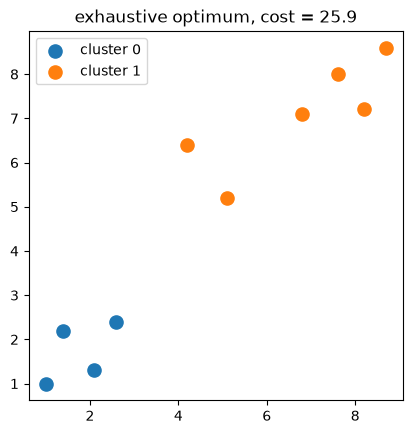

In [31]:
import matplotlib.pyplot as plt


def plot_clusters(D, blocks, title):
    colors = ["tab:blue", "tab:orange", "tab:green"]
    for r, block in enumerate(blocks):
        plt.scatter([D[i][0] for i in block], [D[i][1] for i in block],
                    color=colors[r % len(colors)], s=90, label=f"cluster {r}")
    plt.legend()
    plt.title(title)
    plt.gca().set_aspect("equal")
    plt.show()


plot_clusters(D, best, f"exhaustive optimum, cost = {best_cost:.1f}")


## 15. Comparing with k-means

k-means is greedy: it alternates "assign each point to its nearest centroid" and
"move each centroid to the mean of its cluster", so it stops at the first partition
that no single move improves. That is a **local** minimum. Since the global optimum
is known here, we can check whether the greedy algorithm found it:


In [32]:
from sklearn.cluster import KMeans

for seed in range(3):
    km = KMeans(n_clusters=2, n_init=1, random_state=seed).fit(D)
    blocks = [[i for i in range(len(D)) if km.labels_[i] == b] for b in range(2)]
    cost = sum(wcss(D, block) for block in blocks)
    print(f"random_state = {seed}: cost = {cost:7.2f}   clusters = {blocks}")

print(f"exhaustive optimum: cost = {best_cost:7.2f}")


random_state = 0: cost =   25.94   clusters = [[4, 5, 6, 7, 8, 9], [0, 1, 2, 3]]
random_state = 1: cost =   25.94   clusters = [[4, 5, 6, 7, 8, 9], [0, 1, 2, 3]]
random_state = 2: cost =   25.94   clusters = [[4, 5, 6, 7, 8, 9], [0, 1, 2, 3]]
exhaustive optimum: cost =   25.94


Every k-means cost is $\ge$ the exhaustive cost, and on this easy data set they
happen to agree with it. Had one of them been larger, we would have caught a local
minimum — something impossible to detect without a reference value. For real data
sets that reference cannot be computed, which is why practice uses several restarts
(`n_init`) and a good initialization (k-means++), and why the number of clusters is
chosen by a separate criterion (silhouette, elbow) rather than by the cost alone.

## 16. Several clusters, and the Stirling count

The same recursion handles $k$ labels, with two changes.

* A labeling counts only if *all* $k$ labels appear, otherwise some cluster is
  empty.
* Relabelings must not be counted again. Fixing the label of point 0 to 0 is not
  enough, because the remaining labels can still be permuted, which over-counts by
  $(k-1)!$. The standard fix is a **restricted growth condition**: a new point may
  take an already used label, or the next unused one, but never a label that has
  not appeared yet. Then every partition corresponds to exactly one labeling, and
  the count must be $S(n,k)$.


In [33]:
def clusterings_k(n, k):
    """All partitions of {0,...,n-1} into exactly k non-empty blocks."""
    z = [0] * n                                   # point 0 is in block 0

    def rec(i):
        if i == n:
            if max(z) + 1 == k:                   # all k blocks are used
                yield [[j for j in range(n) if z[j] == b] for b in range(k)]
            return
        for label in range(min(max(z[:i]) + 2, k)):   # old labels, or the next one
            z[i] = label
            yield from rec(i + 1)

    yield from rec(1)


In [34]:
for n in range(3, 8):
    print(f"n = {n}:", [sum(1 for _ in clusterings_k(n, k)) for k in range(1, n + 1)])


n = 3: [1, 3, 1]
n = 4: [1, 7, 6, 1]
n = 5: [1, 15, 25, 10, 1]
n = 6: [1, 31, 90, 65, 15, 1]
n = 7: [1, 63, 301, 350, 140, 21, 1]


Compare with the rows of the Stirling triangle computed from the recurrence:


In [35]:
for n in range(3, 8):
    print(f"n = {n}:", [S(n, k) for k in range(1, n + 1)])


n = 3: [1, 3, 1]
n = 4: [1, 7, 6, 1]
n = 5: [1, 15, 25, 10, 1]
n = 6: [1, 31, 90, 65, 15, 1]
n = 7: [1, 63, 301, 350, 140, 21, 1]


The two triangles are equal, so the enumeration is correct and the $k^n$
labelings collapse to $S(n,k)$ partitions. The size of the search space for a real
problem is another matter:


In [36]:
print(f"{'n':>4} {'k':>3} {'k**n':>12} {'S(n,k)':>12}")
for n, k in [(10, 2), (10, 3), (15, 3), (20, 4), (50, 5), (150, 3)]:
    print(f"{n:>4} {k:>3} {k ** n:>12.2e} {S(n, k):>12.2e}")


   n   k         k**n       S(n,k)
  10   2     1.02e+03     5.11e+02
  10   3     5.90e+04     9.33e+03
  15   3     1.43e+07     2.38e+06
  20   4     1.10e+12     4.52e+10
  50   5     8.88e+34     7.40e+32
 150   3     3.70e+71     6.17e+70


$S(150,3)\approx 6.2\times10^{70}$: no exhaustive search will ever finish. In
practice k-means, hierarchical clustering or LVQ produce a *good* partition in
polynomial time, and we accept that it may not be the best one.

## 17. Constraints, and why pruning matters

Everything so far walks the *whole* tree of decisions: $2^n$ leaves for bits,
$S(n,k)$ for partitions. When a problem has **hard constraints**, we can test a
partial assignment and abandon the branch before it is completed. That check is
called **pruning**, and it is the difference between a search that runs and one
that does not. The cleanest place to see it is the *N-queen* problem.

Place $n$ queens on an $n\times n$ board so that no two attack each other. Two
queens attack if they share a row, a column, or a diagonal.

Number rows and columns $0,\ldots,n-1$. Since no two queens may share a row, put
exactly one queen in every row; the only unknown is its column. So a candidate is

$$x=(x_0,x_1,\ldots,x_{n-1}),\qquad x_i\in\{0,\ldots,n-1\},$$

where $x_i$ is the column of the queen in row $i$. For $n=4$, the vector
`[1, 3, 0, 2]` means column 1 in row 0, column 3 in row 1, column 0 in row 2,
column 2 in row 3.

Ignoring the "no shared column" rule there are $n^n$ vectors; with it, only the
permutations, $n!$ of them:


In [37]:
print(f"{'n':>3} {'n**n':>22} {'n!':>22}")
for n in [4, 6, 8, 10, 12, 16]:
    print(f"{n:>3} {n ** n:>22} {math.factorial(n):>22}")


  n                   n**n                     n!
  4                    256                     24
  6                  46656                    720
  8               16777216                  40320
 10            10000000000                3628800
 12          8916100448256              479001600
 16   18446744073709551616         20922789888000


$8^8=16\,777\,216$ but $8!=40\,320$: the column rule alone removes $99.8\%$ of
the candidates. Checking partial boards removes almost all of the rest.

### The safety test

Suppose rows $0,\ldots,i-1$ already hold queens in columns $x_0,\ldots,x_{i-1}$,
and we want to put a queen in row $i$, column $j$. The placement is safe if, for
every earlier row $k<i$:

* **column**: $x_k \neq j$;
* **diagonal**: two queens share a diagonal exactly when the vertical distance
  equals the horizontal one, $|x_k-j| = |k-i|$, which covers both slopes.

Note what is *not* checked: the row, because row $i$ holds a single queen by
construction, and rows $k>i$, because they are still empty. Only the past matters
— a general principle of backtracking.


In [38]:
def is_safe(x, i, j):
    """Can the queen of row i be put in column j, given rows 0..i-1?"""
    for k in range(i):
        if x[k] == j:                        # same column
            return False
        if abs(x[k] - j) == abs(k - i):      # same diagonal
            return False
    return True


`x` may be longer than $i$; the entries $x_k$ with $k\ge i$ are never read, which
is exactly why we may fill the vector as we go.

### Backtracking

At level $i$ we try every column $j$; if the placement is safe we write
`x[i] = j` and recurse to level $i+1$. When we come back, the next $j$ overwrites
`x[i]`, so no "undo" is needed. At level $n$ every row is filled and every test has
passed, so the vector is a solution.


In [39]:
def nqueen(i, x):
    """Print all solutions whose first i rows are x[0..i-1]."""
    n = len(x)
    if i == n:                 # base case: a complete, safe placement
        print(x)
        return
    for j in range(n):
        if is_safe(x, i, j):
            x[i] = j
            nqueen(i + 1, x)


nqueen(0, [-1] * 4)


[1, 3, 0, 2]
[2, 0, 3, 1]


For $n=4$ the two printed vectors, `[1, 3, 0, 2]` and `[2, 0, 3, 1]`, are mirror
images of each other. For $n=2$ and $n=3$ nothing is printed: no solution exists.
Counting how often the function is entered shows what pruning is worth:


In [40]:
nodes = 0


def nqueen_count(i, x):
    global nodes
    nodes += 1
    n = len(x)
    if i == n:
        return 1
    total = 0
    for j in range(n):
        if is_safe(x, i, j):
            x[i] = j
            total += nqueen_count(i + 1, x)
    return total


for n in [4, 6, 8, 10]:
    nodes = 0
    solutions = nqueen_count(0, [-1] * n)
    print(f"n = {n:>2}   solutions = {solutions:>4}   "
          f"nodes visited = {nodes:>8}   n**n = {n ** n:>12}")


n =  4   solutions =    2   nodes visited =       17   n**n =          256
n =  6   solutions =    4   nodes visited =      153   n**n =        46656
n =  8   solutions =   92   nodes visited =     2057   n**n =     16777216


n = 10   solutions =  724   nodes visited =    35539   n**n =  10000000000


With $n=10$ there are $10^{10}$ vectors in the space but only 35 539 nodes are
visited. The constraints are used **before** the work is done, not after. The
counts of solutions, $1, 0, 0, 2, 10, 4, 40, 92, 352, 724$, are not monotone —
there are fewer solutions for $n=6$ than for $n=5$ — which is why such problems are
solved by search and not by a formula.

A board can be printed as text, which also works in slides and on paper:


In [41]:
def print_board(x):
    n = len(x)
    for i in range(n):
        print(" ".join("Q" if x[i] == j else "." for j in range(n)))
    print()


print_board([1, 3, 0, 2])


. Q . .
. . . Q
Q . . .
. . Q .



### From hard constraints to a soft objective

So far a candidate is either a solution or not. Many real problems have no
candidate that satisfies everything, and then the question becomes *how badly* a
candidate violates the rules. That number is an **objective** (a cost) to minimize,
and the search becomes an optimization problem. For the queens, the natural cost of
a complete assignment is the number of attacking pairs:


In [42]:
def count_conflicts(x):
    """Number of attacking pairs of queens in a complete assignment x."""
    n = len(x)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            if x[i] == x[j] or abs(x[i] - x[j]) == abs(i - j):
                pairs.append((i, j))
    return len(pairs), pairs


conflicts, pairs = count_conflicts([1, 3, 0, 2])
print("a solution              -> conflicts:", conflicts)

conflicts, pairs = count_conflicts(list(range(8)))
print("all on the main diagonal -> conflicts:", conflicts)
print("first three attacking pairs:", pairs[:3])


a solution              -> conflicts: 0
all on the main diagonal -> conflicts: 28
first three attacking pairs: [(0, 1), (0, 2), (0, 3)]


A solution has cost 0, while the assignment with every queen on the main diagonal
has every pair attacking: $\binom{8}{2}=28$. With a cost function we may drop the
safety test and use a *local* search: move a queen so that the number of conflicts
decreases. It usually finds *a* solution, but it can get stuck in a local minimum,
exactly like k-means.

This is the bridge to clustering. In clustering there are **no hard constraints**:
every labeling is a legal clustering, and among the $S(n,k)$ clusterings we look for
the one of smallest cost. So can we prune here at all? Yes, with one observation:
adding a point to a cluster never *lowers* its $W$, because

$$W(C\cup\{\mathbf{x}\}) = W(C) + \frac{|C|}{|C|+1}\,d(\mathbf{x},\boldsymbol\mu_C)^2 .$$

The cost of the points assigned so far is therefore a **lower bound** for every
completion of that branch. If it already exceeds the best cost found, the branch
cannot win and we abandon it:


In [43]:
def bf_clustering_2_pruned(D):
    """The same optimum as bf_clustering_2, but abandoning hopeless branches."""
    n = len(D)
    z = [0] * n
    best_cost, best_z, nodes = math.inf, None, 0

    def partial_cost(i):
        # cost of the first i points, using the clusters they are in so far
        return sum(wcss(D, [j for j in range(i) if z[j] == b]) for b in (0, 1))

    def rec(i):
        nonlocal best_cost, best_z, nodes
        nodes += 1
        if partial_cost(i) >= best_cost:      # a completion cannot be cheaper
            return
        if i == n:
            best_cost, best_z = partial_cost(n), list(z)
            return
        for label in (0, 1):
            z[i] = label
            rec(i + 1)

    rec(0)
    return best_z, best_cost, nodes


D = [(1.0, 1.0), (1.4, 2.2), (2.1, 1.3), (2.6, 2.4),
     (6.8, 7.1), (7.6, 8.0), (8.2, 7.2), (8.7, 8.6),
     (4.2, 6.4), (5.1, 5.2)]

z, cost, nodes = bf_clustering_2_pruned(D)
blocks = [[i for i in range(len(D)) if z[i] == b] for b in (0, 1)]
print("clusters:", blocks)
print(f"cost = {cost:.3f}")
print("nodes visited:", nodes)
print("leaves without pruning:", 2 ** len(D))
print("leaves after removing the label symmetry:", 2 ** (len(D) - 1) - 1)


clusters: [[0, 1, 2, 3], [4, 5, 6, 7, 8, 9]]
cost = 25.937
nodes visited: 137
leaves without pruning: 1024
leaves after removing the label symmetry: 511


The optimum is the same, and pruning visited only 137 nodes, against 511 candidate
partitions and 1024 raw labelings. The saving grows with $n$, but it does **not** change the
exponential nature of the problem: pruning is a constant factor on a function that
grows like $2^n$. For $n=150$ the constant does not matter at all — which is why
k-means exists.

## 18. What we learned

* A clustering is a *partition*; a program represents it as a label vector, and
  labels are arbitrary names, so $k!$ label vectors describe one partition and a
  constant vector describes one cluster, not $k$.
* The number of partitions of $n$ points into $k$ non-empty clusters is the
  Stirling number $S(n,k)$; the number of labelings is $k^n$. Two clusters are
  special, $S(n,2)=2^{n-1}-1$.
* Recursion is how we enumerate a space of $n$ decisions without writing $n$
  loops; a generator hands the results out one by one; memoization avoids
  recomputing the same subproblem. The two classic beginner bugs are `return`
  instead of `yield`, and storing references to a shared buffer.
* Exhaustive search is exact but feasible only for very small $n$. Its value is to
  *define* the optimization problem and to *test* heuristics such as k-means.
* Constraints prune a search, and the partial cost of a clustering is a valid
  lower bound, so the same trick applies here — as a constant factor, not as a
  cure.

## Exercises

1. `SAT_Table_ref` stores eight references to one list. Repair it in two different
   ways (a copy, and a generator) and check that the eight rows are distinct
   objects.
2. Change `SAT_Table` so that every variable takes the values $0,1,2$. How many
   rows does it print for $n=4$? How many in general?
3. Prove $S(n,2)=2^{n-1}-1$ (hint: in a partition into two blocks, decide for each
   of the points $2,\ldots,n$ whether it joins the block of point 1).
4. Prove and check numerically the Bell recurrence
   $B_{n+1} = \sum_{j=0}^{n}\binom{n}{j} B_j$.
5. Rewrite `bf_clustering_2` so that it also returns the *second* best clustering.
   Why might that be useful?
6. Write `bf_clustering_k(D, k)` from `clusterings_k` and `wcss` and run it on the
   ten points of Section 14 with $k=3$. (Warning: $S(10,3)=9330$ candidates.)
7. Replace WCSS by the sum of *distances* (not squared) and check whether the
   optimal 2-clustering of Section 14 changes; Hastie et al., Sec. 14.3.5, use this
   variant.
8. In `bf_clustering_2_pruned`, the branch is cut when the partial cost reaches the
   best cost. Why must the comparison be `>=` and not `>`? What happens if the best
   clustering is met several times?
9. Rewrite `is_safe` with a formula that avoids `abs` (hint: the two diagonals have
   constant $i-j$ and constant $i+j$). Why is that version faster?
10. How many 2-clusterings does a data set with $n=20$ points have, and how long
    would scoring them take at $10^6$ per second? And $n=40$ at $10^9$ per second?

## Sources

- T. Hastie, R. Tibshirani, J. Friedman, *The Elements of Statistical Learning*,
  Sec. 14.3 (cluster analysis, combinatorial view).
- {cite}`zaki2020data`, Ch. 17 (clustering; the remark that there are about
  $k^n/k!$ clusterings of $n$ points into $k$ groups).

